In [38]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import matplotlib.pyplot as plt
import torch


# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import src.rl.evaluate_cql_alpha_sweep as eval_cql
import src.rl.evaluate_terminal_reward_models as etm
import src.rl.evaluate_bc_final_seeds as eval_bc
import src.rl.clinician_baseline as clin_baseline
import src.rl.check_std_floor as std_check

import src.rl.action_distribution_sweep as action_dist
import src.rl.dose_histogram_by_alpha as dose_hist

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [22]:
cohort = "picu"
# health_cohort = "sepsis_picu"
health_cohort = "picu" # dynamic deephit trained on all picu patients, not just sepsis patients

if cohort == "picu":    
    bc_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/bc_with_logprobs/split_0/sepsis/intake-vis/picu_patients"
    print(f"Using bc_dir: {bc_dir}")
    dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model"
    print(f"Using dynamic_deephit_model_dir: {dynamic_deephit_model_dir}")


else:
    raise ValueError(f"Unknown cohort: {cohort}")

# first, load the dynamic deephit hyperparameters so we can get the state dimension
dynamic_deephit_dir = eval_cql.get_model_dirs(dynamic_deephit_model_dir)[0]
print(f"Dynamic DeepHit model directory: {dynamic_deephit_dir}")
# load results.json from dynamic_deephit_dir
with open(os.path.join(dynamic_deephit_dir, "results.json"), "r") as f:
    dynamic_deephit_results = json.load(f)
state_dim = dynamic_deephit_results['hyperparameters']['d_model']
print(f"State dimension from dynamic deephit hyperparameters: {state_dim}")

# find folder inside bc_dir that ends "with_seeds"
bc_with_seeds_dir = None
for folder in os.listdir(bc_dir):
    if folder.endswith("with_seeds"):
        bc_with_seeds_dir = os.path.join(bc_dir, folder)
        break

if bc_with_seeds_dir is None:
    raise ValueError("Could not find folder in bc_dir that ends with 'with_seeds'")

print(f"BC with seeds directory: {bc_with_seeds_dir}")

bc_model_dirs = etm.get_model_dirs(bc_with_seeds_dir)

print(f"BC model directories: {bc_model_dirs}")

bc_models = []
for model_dir in bc_model_dirs:
    # load health score sarsa model
    actor, config_manager, hyperparams = eval_bc.load_actor(reward_type='health_score', model_dir=model_dir, state_dim=state_dim)
    bc_models.append((actor, config_manager, hyperparams))


Using bc_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/bc_with_logprobs/split_0/sepsis/intake-vis/picu_patients
Using dynamic_deephit_model_dir: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model
No choc directories found in /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model
Found model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_20260821-202508_49e52257
Dynamic DeepHit model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_20260821-202508_49e52257
State dimension from dynamic deephit hyperparameters: 128
BC with seeds directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/bc_with_logprobs/split_0/sepsis/

# Load data

In [12]:
config_manager.data_config['unit_stay_ids_path'] = os.path.join(
    config_manager.get_data_dir, 'cohorts',
    'icu_units',
    f"{config_manager.unit.lower()}_stay_ids.csv"
)

config_manager.data_config['age_stay_ids_path'] = os.path.join(
    config_manager.get_data_dir, 'cohorts',
    'age', 'pediatric_stay_ids.csv'
)

processors = {}
processors['train'], processors['val'], processors['test'] = etm.load_data(config_manager, hyperparams)  

Dataset type 'bc_latents' is not an attribute of the class.
Dataset type 'bc_latents' is not an attribute of the class.
Dataset type 'bc_latents' is not an attribute of the class.
Dataset type 'bc_latents' is not an attribute of the class.
Dataset type 'bc_latents' is not an attribute of the class.
Dataset type 'bc_latents' is not an attribute of the class.
Dataset type 'bc_latents' is not an attribute of the class.
Dataset type 'bc_latents' is not an attribute of the class.
Dataset type 'bc_latents' is not an attribute of the class.


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type


In [15]:
# real clinician non-zero fluid doses, from training data
fluid_doses = processors['train'].rl_dataset["actions"][:, 0]
nonzero_fluid = fluid_doses[fluid_doses > 1e-4]

# clamp to avoid inf at exact 0/1 boundaries, then invert the sigmoid (logit)
nonzero_fluid_clamped = nonzero_fluid.clamp(1e-4, 1 - 1e-4)
raw_fluid = torch.logit(nonzero_fluid_clamped)

print(f"Fluid: dose-space std={nonzero_fluid.std():.4f}, "
      f"raw-space std={raw_fluid.std():.4f}, raw-space mean={raw_fluid.mean():.4f}")

# same for vaso
vaso_doses = processors['train'].rl_dataset["actions"][:, 1]
nonzero_vaso = vaso_doses[vaso_doses > 1e-4]
nonzero_vaso_clamped = nonzero_vaso.clamp(1e-4, 1 - 1e-4)
raw_vaso = torch.logit(nonzero_vaso_clamped)

print(f"Vaso: dose-space std={nonzero_vaso.std():.4f}, "
      f"raw-space std={raw_vaso.std():.4f}, raw-space mean={raw_vaso.mean():.4f}")

actions = processors['train'].rl_dataset['actions']

fluids = actions[:, 0]
vasopressors = actions[:, 1] 

# get min non-zero fluid and vasopressor doses
min_nonzero_fluid = fluids[fluids > 0].min()
min_nonzero_vasopressor = vasopressors[vasopressors > 0].min()

print(f"Min non-zero fluid dose: {min_nonzero_fluid}")
print(f"Min non-zero vasopressor dose: {min_nonzero_vasopressor}")

clinician_baseline_val = clin_baseline.compute_clinician_baseline(processors['val'].rl_dataset["actions"])
clin_baseline.print_clinician_baseline(clinician_baseline_val, label="val")

clinician_baseline_test = clin_baseline.compute_clinician_baseline(processors['test'].rl_dataset["actions"])
clin_baseline.print_clinician_baseline(clinician_baseline_test, label="test")

Fluid: dose-space std=0.1420, raw-space std=0.6721, raw-space mean=0.1841
Vaso: dose-space std=0.1158, raw-space std=0.6342, raw-space mean=-1.0675
Min non-zero fluid dose: 0.0001319456350756809
Min non-zero vasopressor dose: 0.006044956389814615
=== Clinician baseline (val) ===
  fluid: rate=90.9%, mean=0.4958, nonzero_mean=0.5456
  vaso: rate=8.3%, mean=0.0213, nonzero_mean=0.2569
=== Clinician baseline (test) ===
  fluid: rate=90.5%, mean=0.4900, nonzero_mean=0.5415
  vaso: rate=9.4%, mean=0.0260, nonzero_mean=0.2775


## health_score

In [16]:
training_health_score = processors['train'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['train'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['train'].dynamic_deephit_predictions['index_ptr'][1:] - 1
training_health_score = np.delete(training_health_score, indices_to_remove)

val_health_score = processors['val'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['val'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['val'].dynamic_deephit_predictions['index_ptr'][1:] - 1
val_health_score = np.delete(val_health_score, indices_to_remove)

test_health_score = processors['test'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['test'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['test'].dynamic_deephit_predictions['index_ptr'][1:] - 1
test_health_score = np.delete(test_health_score, indices_to_remove)

training_actions = processors['train'].rl_dataset["actions"]

# standard deviation
### ""

Floor std = 0.1353, Ceiling std = 2.7183

Seed    Drug        mean     std     min     max  median   %floor   %ceil
-----------------------------------------------------------------------
1       Fluid     0.5385  0.2089  0.1568  1.8088  0.4990     0.0%    0.0%
1       Vaso      0.4713  0.1355  0.2106  1.6053  0.4449     0.0%    0.0%
2       Fluid     0.5426  0.2073  0.1481  1.7924  0.5066     0.0%    0.0%
2       Vaso      0.4767  0.1379  0.2182  1.8212  0.4490     0.0%    0.0%
3       Fluid     0.5470  0.2100  0.1535  1.7458  0.5050     0.0%    0.0%
3       Vaso      0.4611  0.1291  0.2358  1.7785  0.4341     0.0%    0.0%
4       Fluid     0.5326  0.2016  0.1449  1.7358  0.4957     0.0%    0.0%
4       Vaso      0.4769  0.1274  0.2257  1.6212  0.4527     0.0%    0.0%
5       Fluid     0.5401  0.2073  0.1546  1.7428  0.5035     0.0%    0.0%
5       Vaso      0.4484  0.1255  0.1929  1.4011  0.4227     0.0%    0.0%

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/bc_wit

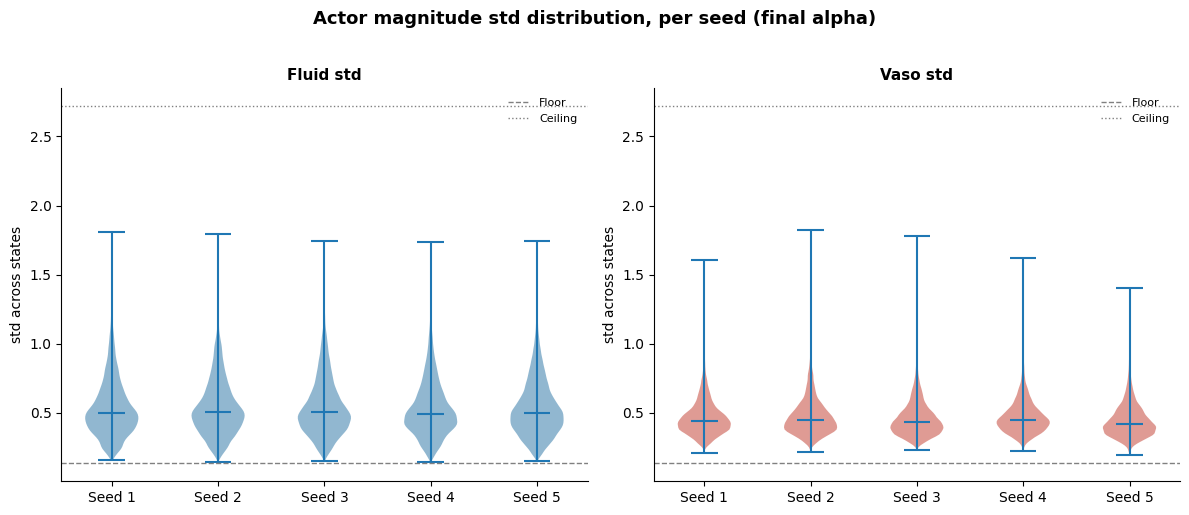

In [29]:
fig = std_check.plot_std_distributions_by_seed(
    bc_models,
    processors['test'],
    save_path=os.path.join(bc_dir, "std_distributions_by_seed_health_score.png"),
)
fig

"Across all 5 final BC seeds, the fitted magnitude distribution's standard deviation — the spread parameter of the raw-space Gaussian each dose is sampled from, not the dose itself — showed no evidence of the floor- or ceiling-collapse pathologies identified and corrected in the CQL actor. Every seed showed 0% of states with this std at either clamp boundary (floor = 0.1353, ceiling = 2.7183) for both drugs, with the mean std across states sitting at 0.53–0.55 for fluid and 0.45–0.48 for vasopressor — somewhat below, but in the same general range as, the real-data-derived target stds computed directly from clinician doses (0.6721 fluid, 0.6342 vasopressor; see Section [X]). Non-degenerate spread was present in the std itself too (std-of-std ≈ 0.13–0.21 across states), and maximum values (1.4–1.8) stayed comfortably clear of the ceiling in every seed.

This is consistent with a fundamental difference in optimization pressure between the two objectives. CQL's actor is trained via -Q_π.mean() evaluated on stochastic action samples; when the critic's Q-surface curves downward even mildly near the actor's current estimate, Jensen's inequality creates an unconditional incentive to shrink sampling variance toward zero, since any spread around the mean looks worse to the critic than sampling exactly at the mean. BC's actor, by contrast, is trained by direct maximum-likelihood estimation against the real, logged clinician doses — correctly representing the true spread of the data is precisely what likelihood maximization rewards, so there is no equivalent incentive to collapse this parameter. The entropy-tuning and mean-saturation regularization ported from CQL's fix provided a second layer of protection, but the clean result here suggests the underlying MLE objective was already well-behaved without needing to rely on it.

This result is directly relevant to weighted importance sampling: log_prob_for_wis uses BC's fitted magnitude standard deviation as the behavior-policy density's bandwidth, so a well-calibrated, non-collapsed std here is a precondition for trustworthy WIS importance weights. This does not by itself guarantee stable WIS estimates, which remain separately subject to the known general instabilities of importance sampling (heavy-tailed weight distributions, effective sample size collapse) independent of density calibration."

=== Clinician baseline (test) ===
  fluid: rate=90.5%, mean=0.4900, nonzero_mean=0.5415
  vaso: rate=9.4%, mean=0.0260, nonzero_mean=0.2775
seed 1/5: fluid[rate=98.7%, mean=0.5320, nonzero_mean=0.5391]  vaso[rate=5.3%, mean=0.0164, nonzero_mean=0.3090]
seed 2/5: fluid[rate=98.6%, mean=0.5319, nonzero_mean=0.5393]  vaso[rate=5.6%, mean=0.0173, nonzero_mean=0.3100]
seed 3/5: fluid[rate=98.4%, mean=0.5327, nonzero_mean=0.5416]  vaso[rate=5.3%, mean=0.0167, nonzero_mean=0.3189]
seed 4/5: fluid[rate=98.6%, mean=0.5301, nonzero_mean=0.5374]  vaso[rate=4.9%, mean=0.0153, nonzero_mean=0.3150]
seed 5/5: fluid[rate=98.5%, mean=0.5298, nonzero_mean=0.5381]  vaso[rate=5.5%, mean=0.0173, nonzero_mean=0.3124]
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/bc_with_logprobs/split_0/sepsis/intake-vis/picu_patients/stage3_actions_bc.png


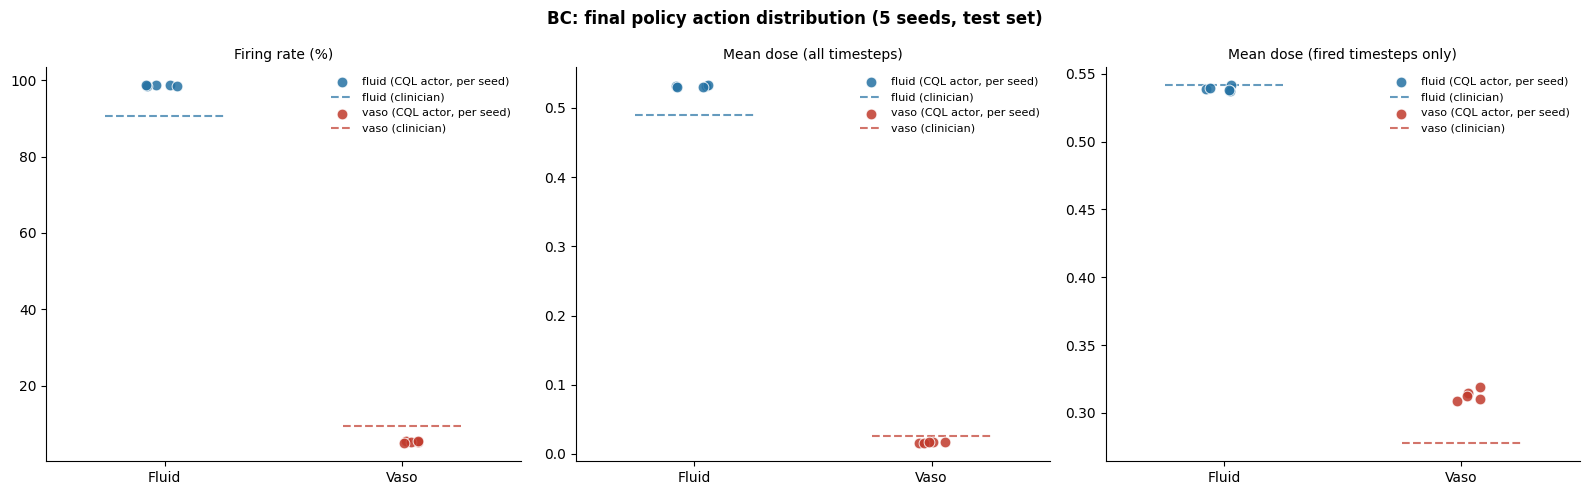

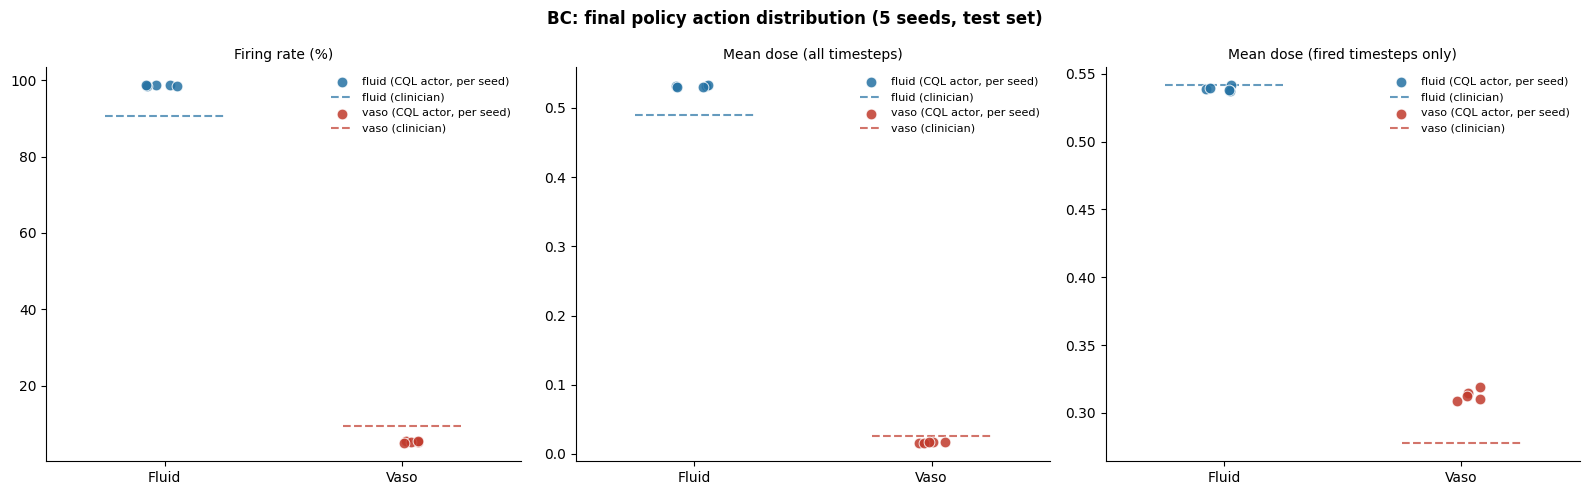

In [43]:
clinician_actions_test = processors['test'].rl_dataset["actions"]
clinician_baseline_test = clin_baseline.compute_clinician_baseline(clinician_actions_test)
clin_baseline.print_clinician_baseline(clinician_baseline_test, label="test")

# 1. Fire rate / mean dose / non-zero mean, both drugs, all 5 seeds vs. clinician baseline
stats_bc, fig_bc = action_dist.run_action_distribution_stage3(
    bc_models,
    processors['test'],
    clinician_baseline=clinician_baseline_test,
    get_actor_actions_fn=eval_bc.get_bc_actor_actions,
    title="BC: final policy action distribution (5 seeds, test set)",
    save_path=os.path.join(bc_dir, "stage3_actions_bc.png"),
)
fig_bc

=== Fluid dose distribution summary (nonzero doses only) ===
  Clinician (real): n=105578, mean=0.5415, std=0.1455, median=0.5658, p10=0.3484, p25=0.4731, p75=0.6289, p90=0.6960
  alpha=0: n=115123, mean=0.5391, std=0.0891, median=0.5501, p10=0.4098, p25=0.4713, p75=0.6058, p90=0.6481
  alpha=1: n=115058, mean=0.5393, std=0.0885, median=0.5517, p10=0.4122, p25=0.4709, p75=0.6050, p90=0.6475
  alpha=2: n=114754, mean=0.5416, std=0.0907, median=0.5546, p10=0.4099, p25=0.4717, p75=0.6090, p90=0.6529
  alpha=3: n=115071, mean=0.5374, std=0.0897, median=0.5497, p10=0.4069, p25=0.4683, p75=0.6042, p90=0.6475
  alpha=4: n=114865, mean=0.5381, std=0.0888, median=0.5491, p10=0.4111, p25=0.4681, p75=0.6051, p90=0.6487
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/bc_with_logprobs/split_0/sepsis/intake-vis/picu_patients/dose_histogram_fluid_bc.png
=== Vaso dose distribution summary (nonzero doses only) ===
  Clinician (real): n=10921, mean=0.2775, std=0.1371, median=0.2411, p10

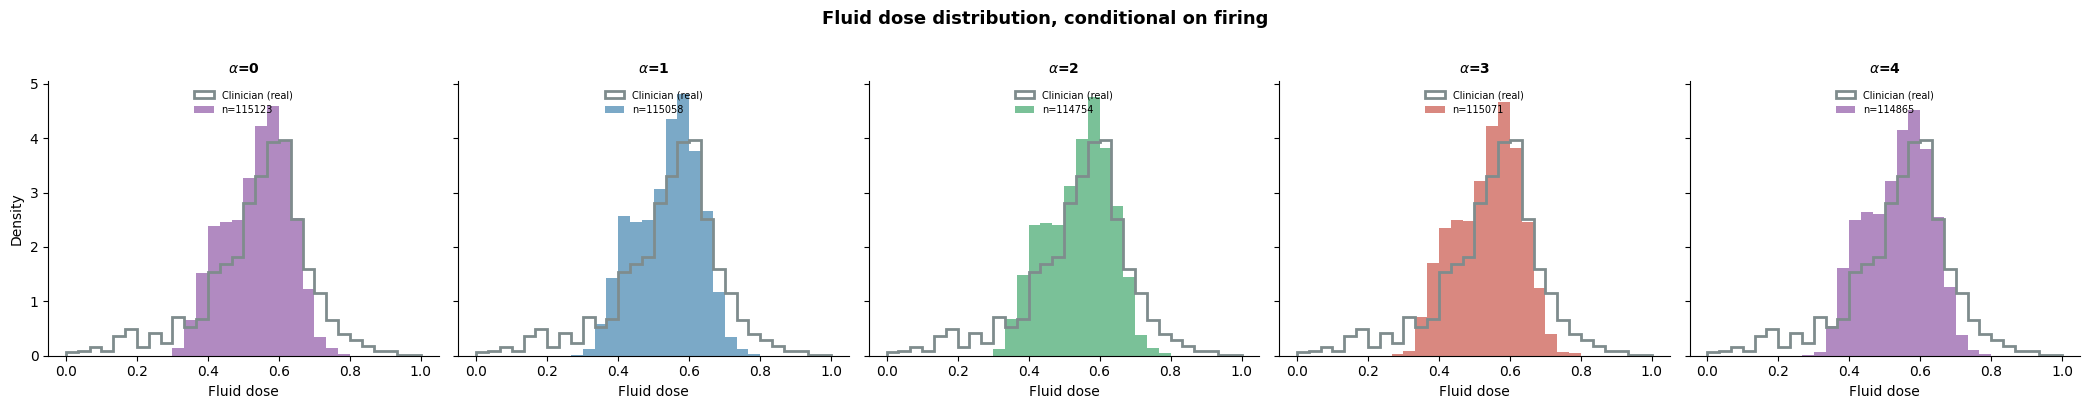

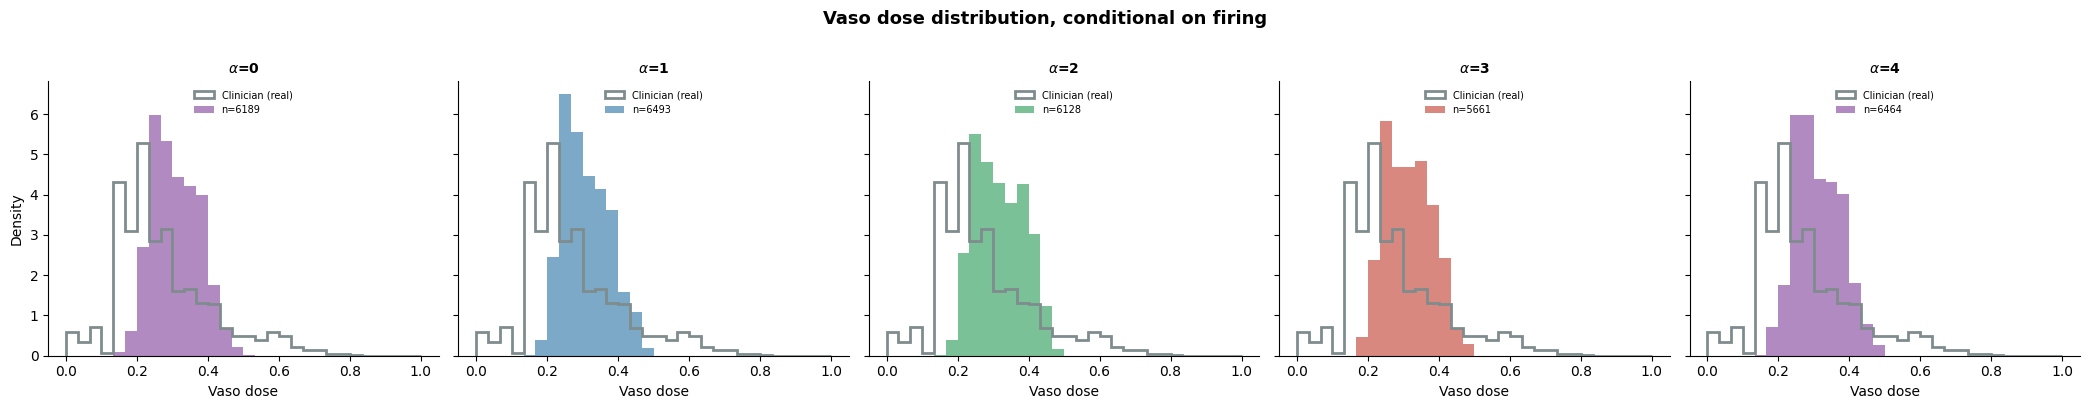

In [44]:
# 2. Full dose distribution shape, conditional on firing (fluid + vaso), per seed
bc_models_by_seed = {i: model_entry for i, model_entry in enumerate(bc_models)}

fig_fluid = dose_hist.plot_dose_histograms(
    bc_models_by_seed,
    processor=processors['test'],
    clinician_actions=clinician_actions_test,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=eval_bc.get_bc_actor_actions,
    n_cols=5,
    save_path=os.path.join(bc_dir, "dose_histogram_fluid_bc.png"),
)

fig_vaso = dose_hist.plot_dose_histograms(
    bc_models_by_seed,
    processor=processors['test'],
    clinician_actions=clinician_actions_test,
    dim=1, dim_name="Vaso",
    get_actor_actions_fn=eval_bc.get_bc_actor_actions,
    n_cols=5,
    save_path=os.path.join(bc_dir, "dose_histogram_vaso_bc.png"),
)

=== Fluid: model dose distribution AT clinician-zero states (n=11084, 9.5% of all states) ===
  alpha=0: agrees (recommends ~0) at 5.7% of clinician-zero states; among the 10455 disagreements, mean dose=0.5033, median=0.5124
  alpha=1: agrees (recommends ~0) at 5.1% of clinician-zero states; among the 10516 disagreements, mean dose=0.5043, median=0.5146
  alpha=2: agrees (recommends ~0) at 6.3% of clinician-zero states; among the 10390 disagreements, mean dose=0.5049, median=0.5158
  alpha=3: agrees (recommends ~0) at 5.4% of clinician-zero states; among the 10486 disagreements, mean dose=0.5017, median=0.5116
  alpha=4: agrees (recommends ~0) at 6.6% of clinician-zero states; among the 10351 disagreements, mean dose=0.5012, median=0.5075
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/bc_with_logprobs/split_0/sepsis/intake-vis/picu_patients/fluid_at_clinician_zero_bc.png
=== Vaso: model dose distribution AT clinician-zero states (n=105741, 90.6% of all states) ===
  a

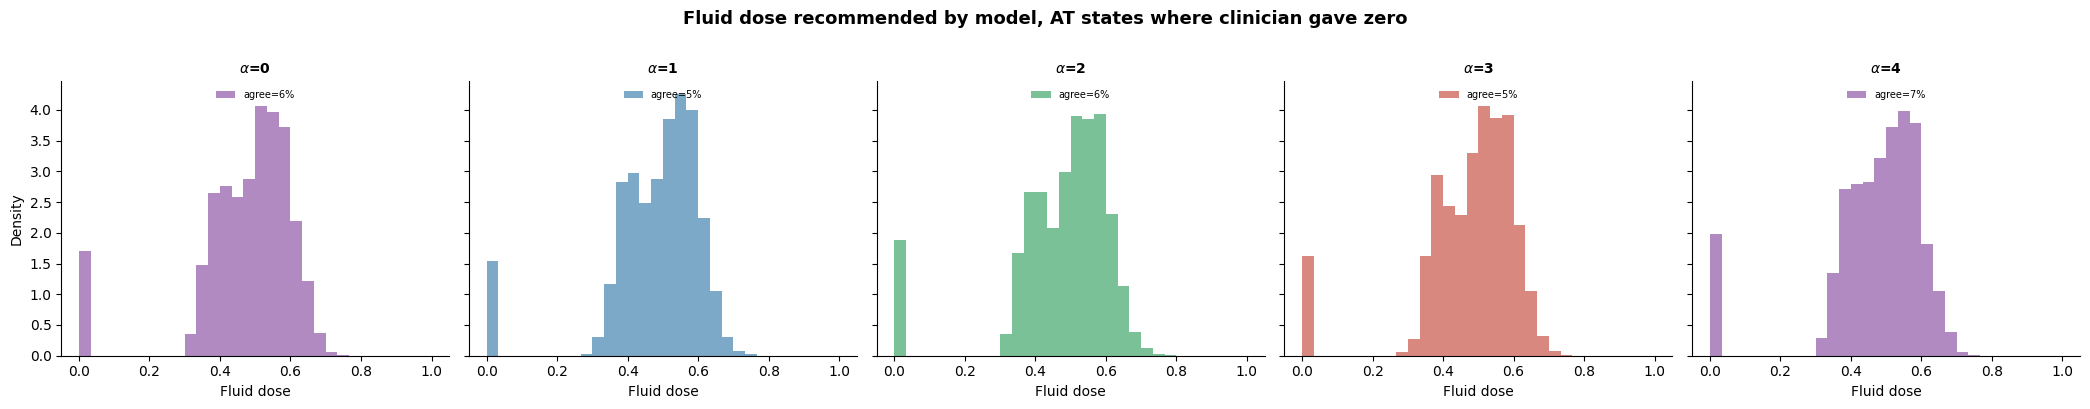

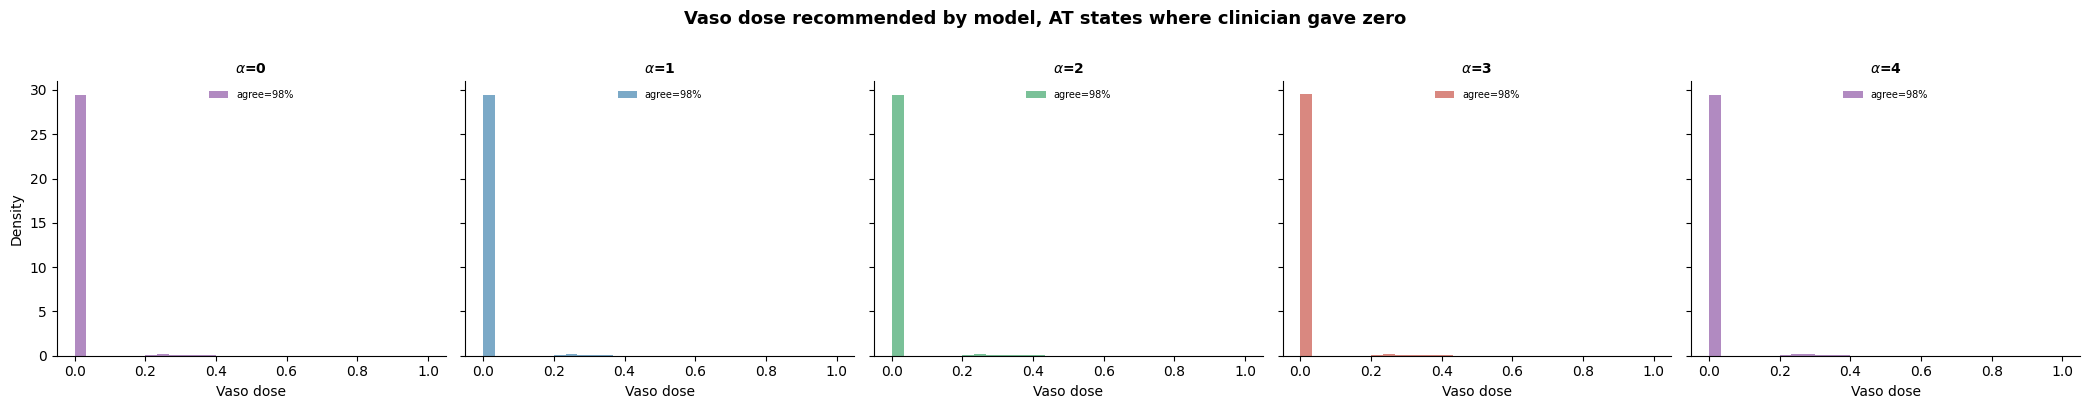

In [45]:
# 3. Does BC ever disagree with the clinician's decision to withhold treatment entirely?
fig_fluid_zero = dose_hist.plot_dose_histograms_at_clinician_zero(
    bc_models_by_seed,
    processor=processors['test'],
    clinician_actions=clinician_actions_test,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=eval_bc.get_bc_actor_actions,
    n_cols=5,
    save_path=os.path.join(bc_dir, "fluid_at_clinician_zero_bc.png"),
)

fig_vaso_zero = dose_hist.plot_dose_histograms_at_clinician_zero(
    bc_models_by_seed,
    processor=processors['test'],
    clinician_actions=clinician_actions_test,
    dim=1, dim_name="Vaso",
    get_actor_actions_fn=eval_bc.get_bc_actor_actions,
    n_cols=5,
    save_path=os.path.join(bc_dir, "vaso_at_clinician_zero_bc.png"),
)

In [50]:
eval_bc.check_gate_calibration_by_seed(
    bc_models,
    processors['test'],
    clinician_actions_test,
)

=== Seed 0 ===
  Fluid gate probability (f_p):
    At clinician-ZERO states:    mean=0.758, median=0.777, p10=0.562, p90=0.933, %>0.5=94.3%
    At clinician-NONZERO states: mean=0.895, median=0.935, p10=0.742, p90=0.983
  Vaso gate probability (f_p):
    At clinician-ZERO states:    mean=0.061, median=0.022, p10=0.013, p90=0.142, %>0.5=1.8%
    At clinician-NONZERO states: mean=0.415, median=0.347, p10=0.061, p90=0.858

=== Seed 1 ===
  Fluid gate probability (f_p):
    At clinician-ZERO states:    mean=0.753, median=0.766, p10=0.562, p90=0.929, %>0.5=94.9%
    At clinician-NONZERO states: mean=0.889, median=0.931, p10=0.728, p90=0.982
  Vaso gate probability (f_p):
    At clinician-ZERO states:    mean=0.062, median=0.022, p10=0.013, p90=0.141, %>0.5=2.0%
    At clinician-NONZERO states: mean=0.422, median=0.367, p10=0.063, p90=0.850

=== Seed 2 ===
  Fluid gate probability (f_p):
    At clinician-ZERO states:    mean=0.741, median=0.753, p10=0.542, p90=0.928, %>0.5=93.7%
    At clini

# 2 possible paths for dealing with fluid's mis-calibration:
1. A genuine model fix — e.g., a class-balanced loss term for the fluid gate specifically (weighting the rare zero-class more heavily in the BCE loss), which could meaningfully shift the whole zero-group distribution down toward the vaso-like pattern. This is a real, targeted, likely-effective fix, but requires retraining.
## or
2. Accept and document this as a known limitation of BC's fluid gate calibration, and check whether it meaningfully affects your WIS results in practice — since WIS ultimately depends on the log-probability of the actual action taken, not just the binary fire decision, it's worth checking empirically whether this calibration gap translates into problematic importance weights before investing in a retrain.

In [51]:
eval_bc.check_fluid_gate_wis_impact(
    bc_models,
    processors['test'],
    clinician_actions_test,
)

=== Seed 0 ===
  Probability BC assigns to the REAL 'no fluid' decision, at clinician-zero-fluid states:
    median=0.223, mean=0.242
  Probability BC assigns to the REAL 'no vaso' decision, at clinician-zero-vaso states (reference -- well calibrated):
    median=0.978, mean=0.939
  Fraction of each trajectory's TOTAL gate log-likelihood magnitude coming from zero-fluid states specifically (n=310 trajectories):
    median=35.7%, mean=38.1%, p90=75.2%

=== Seed 1 ===
  Probability BC assigns to the REAL 'no fluid' decision, at clinician-zero-fluid states:
    median=0.234, mean=0.247
  Probability BC assigns to the REAL 'no vaso' decision, at clinician-zero-vaso states (reference -- well calibrated):
    median=0.978, mean=0.938
  Fraction of each trajectory's TOTAL gate log-likelihood magnitude coming from zero-fluid states specifically (n=310 trajectories):
    median=36.0%, mean=37.2%, p90=73.8%

=== Seed 2 ===
  Probability BC assigns to the REAL 'no fluid' decision, at clinician-ze